# Square output-composition panels

The authors requested square PNG exports for the two horizontal bar charts shown as panels 1D and 1F. Their registered manuscript source names are figure_2d_neutrophil_output and figure_2f_monocyte_output. This focused revision retains the original data, order, colors, bar heights, vertical plotting geometry and font sizes. Only horizontal layout and export bounds change.

Environment manager: micromamba; environment: **chronoclone**; absolute MacBook path: `/path/to/ChronoClone/.runtime/chronoclone`; kernel: **chronoclone-paper**. Actual package versions are printed below.

Execution command:
```sh
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/analysis_workspace/weinreb/20260915_square_output_panels/square_output_panels.ipynb
```

Source plotting code: `ChronoClone_paper/analysis/weinreb/current_source/v3_display/0001_manuscript_panels_and_evidence.ipynb`, cells 77 and 79 (zero-based). The original source notebook and manuscript assets are preserved.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform, importlib.metadata as im
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/weinreb/20260915_square_output_panels'
FIG=OUT/'figures'
FIG.mkdir(exist_ok=True)
(OUT/'tables').mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'matplotlib_cache')
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
from PIL import Image
import xml.etree.ElementTree as ET
from IPython.display import display
ENV=ROOT/'.runtime/chronoclone'
assert Path(sys.executable).resolve()==(ENV/'bin/python').resolve()
print({'environment':'chronoclone','manager':'micromamba','path':str(ENV),'kernel':'chronoclone-paper','Python':platform.python_version(),**{p:im.version(p) for p in ['numpy','pandas','matplotlib','Pillow','nbformat','nbclient']}})
PALETTE=pd.read_csv(ROOT/'ChronoClone_paper/analysis/weinreb/inputs/manuscript_metaclone_palette.csv').set_index('label').color.to_dict()
DISPLAY_COLORS={'Neu':'#ec8b23','Mono':'#c83f59','Ery':'#408bc0','Baso':'#289646','Mast':'#874dad'}
mpl.rcParams.update({'svg.fonttype':'none','font.family':'DejaVu Sans','font.size':13,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','savefig.facecolor':'white'})
def sha256(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
panel_records=[]


Matplotlib is building the font cache; this may take a moment.


{'environment': 'chronoclone', 'manager': 'micromamba', 'path': '/path/to/ChronoClone/.runtime/chronoclone', 'kernel': 'chronoclone-paper', 'Python': '3.11.15', 'numpy': '2.4.6', 'pandas': '2.3.3', 'matplotlib': '3.11.0', 'Pillow': '12.2.0', 'nbformat': '5.10.4', 'nbclient': '0.11.0'}


## Panel 1D

{'original_png': (2189, 1185), 'square_png': (1185, 1185), 'figure_height_inches': np.float64(3.6), 'label_points': 13, 'legend_points': 11.5}


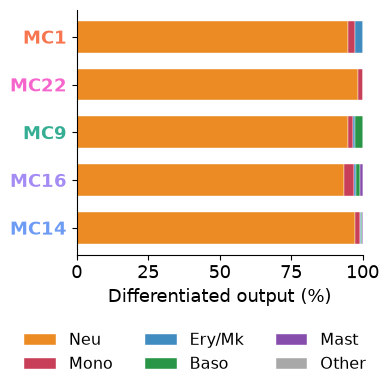

/path/to/ChronoClone/analysis_workspace/weinreb/20260915_square_output_panels/figures/figure_2d_neutrophil_output.svg


In [2]:
STEM='figure_2d_neutrophil_output'
source=ROOT/'ChronoClone_paper/analysis/weinreb/inputs/reference_figure2'/'fig2d_output_composition.csv'
order=[1, 22, 9, 16, 14]
plot_data=pd.read_csv(source).set_index('metaclone').loc[order]
categories=['Neu','Mono','Ery/Mk','Baso','Mast','Other']
assert np.allclose(plot_data[categories].sum(axis=1),1,atol=1e-9)
colors={'Neu':DISPLAY_COLORS['Neu'],'Mono':DISPLAY_COLORS['Mono'],'Ery/Mk':DISPLAY_COLORS['Ery'],'Baso':DISPLAY_COLORS['Baso'],'Mast':DISPLAY_COLORS['Mast'],'Other':'#a8a8a8'}
# Read the original exported height; no result is hard-coded.
original_svg=ROOT/'ChronoClone_paper/manuscript/figures'/f'{STEM}.svg'
original_png=original_svg.with_suffix('.png')
svg_root=ET.parse(original_svg).getroot()
height_pt=float(svg_root.attrib['height'].removesuffix('pt'))
side_inches=height_pt/72
original_size=Image.open(original_png).size
# Retain the original 3.6-inch figure height and vertical axes positions.
# The square export includes the same original lower legend margin.
fig,ax=plt.subplots(figsize=(side_inches,3.6))
fig.subplots_adjust(left=(56.928125/72)/side_inches,
                    right=1-(21.766875/72)/side_inches,
                    top=.96,bottom=.28)
y=np.arange(len(order));left=np.zeros(len(order))
for state in categories:
    value=plot_data[state].to_numpy()*100
    ax.barh(y,value,left=left,color=colors[state],height=.66,edgecolor='white',linewidth=.3,label=state)
    left+=value
ax.set_yticks(y,[f'MC{mc}' for mc in order]);ax.invert_yaxis()
for tick,mc in zip(ax.get_yticklabels(),order): tick.set_color(PALETTE[f'MC{mc}']);tick.set_fontweight('bold')
ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Differentiated output (%)')
ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,.28-.26*(.96-.28)),bbox_transform=fig.transFigure,frameon=False,fontsize=11.5)
plot_data.reset_index().to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
# A fixed square bounding box prevents tight cropping from changing dimensions.
export_top=3.6*.96+.13
export_bbox=Bbox.from_bounds(0,export_top-side_inches,side_inches,side_inches)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches=export_bbox,pad_inches=0)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches=export_bbox,pad_inches=0)
assert Image.open(FIG/f'{STEM}.png').size==(original_size[1],original_size[1])
assert all(t.get_fontsize()==13 for t in ax.get_xticklabels()+ax.get_yticklabels()+[ax.xaxis.label])
assert all(t.get_fontsize()==11.5 for t in ax.get_legend().get_texts())
print({'original_png':original_size,'square_png':Image.open(FIG/f'{STEM}.png').size,'figure_height_inches':fig.get_figheight(),'label_points':13,'legend_points':11.5})
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Square export; original height, vertical geometry, font sizes and proportions unchanged','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

## Panel 1F

{'original_png': (2189, 1185), 'square_png': (1185, 1185), 'figure_height_inches': np.float64(3.6), 'label_points': 13, 'legend_points': 11.5}


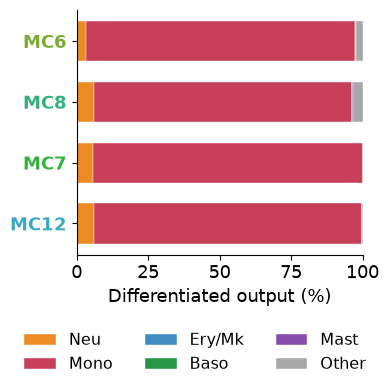

/path/to/ChronoClone/analysis_workspace/weinreb/20260915_square_output_panels/figures/figure_2f_monocyte_output.svg


In [3]:
STEM='figure_2f_monocyte_output'
source=ROOT/'ChronoClone_paper/analysis/weinreb/inputs/reference_figure2'/'fig2e_output_composition.csv'
order=[6, 8, 7, 12]
plot_data=pd.read_csv(source).set_index('metaclone').loc[order]
categories=['Neu','Mono','Ery/Mk','Baso','Mast','Other']
assert np.allclose(plot_data[categories].sum(axis=1),1,atol=1e-9)
colors={'Neu':DISPLAY_COLORS['Neu'],'Mono':DISPLAY_COLORS['Mono'],'Ery/Mk':DISPLAY_COLORS['Ery'],'Baso':DISPLAY_COLORS['Baso'],'Mast':DISPLAY_COLORS['Mast'],'Other':'#a8a8a8'}
# Read the original exported height; no result is hard-coded.
original_svg=ROOT/'ChronoClone_paper/manuscript/figures'/f'{STEM}.svg'
original_png=original_svg.with_suffix('.png')
svg_root=ET.parse(original_svg).getroot()
height_pt=float(svg_root.attrib['height'].removesuffix('pt'))
side_inches=height_pt/72
original_size=Image.open(original_png).size
# Retain the original 3.6-inch figure height and vertical axes positions.
# The square export includes the same original lower legend margin.
fig,ax=plt.subplots(figsize=(side_inches,3.6))
fig.subplots_adjust(left=(56.928125/72)/side_inches,
                    right=1-(21.766875/72)/side_inches,
                    top=.96,bottom=.28)
y=np.arange(len(order));left=np.zeros(len(order))
for state in categories:
    value=plot_data[state].to_numpy()*100
    ax.barh(y,value,left=left,color=colors[state],height=.66,edgecolor='white',linewidth=.3,label=state)
    left+=value
ax.set_yticks(y,[f'MC{mc}' for mc in order]);ax.invert_yaxis()
for tick,mc in zip(ax.get_yticklabels(),order): tick.set_color(PALETTE[f'MC{mc}']);tick.set_fontweight('bold')
ax.set_xlim(0,100);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Differentiated output (%)')
ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,.28-.26*(.96-.28)),bbox_transform=fig.transFigure,frameon=False,fontsize=11.5)
plot_data.reset_index().to_csv(OUT/'tables'/f'{STEM}.csv',index=False)
# A fixed square bounding box prevents tight cropping from changing dimensions.
export_top=3.6*.96+.13
export_bbox=Bbox.from_bounds(0,export_top-side_inches,side_inches,side_inches)
fig.savefig(FIG/f'{STEM}.svg',bbox_inches=export_bbox,pad_inches=0)
fig.savefig(FIG/f'{STEM}.png',dpi=300,bbox_inches=export_bbox,pad_inches=0)
assert Image.open(FIG/f'{STEM}.png').size==(original_size[1],original_size[1])
assert all(t.get_fontsize()==13 for t in ax.get_xticklabels()+ax.get_yticklabels()+[ax.xaxis.label])
assert all(t.get_fontsize()==11.5 for t in ax.get_legend().get_texts())
print({'original_png':original_size,'square_png':Image.open(FIG/f'{STEM}.png').size,'figure_height_inches':fig.get_figheight(),'label_points':13,'legend_points':11.5})
display(fig);plt.close(fig)
panel_records.append({'stem':STEM,'source':str(source.relative_to(ROOT)),'source_sha256':sha256(source),'change':'Square export; original height, vertical geometry, font sizes and proportions unchanged','svg_sha256':sha256(FIG/f'{STEM}.svg'),'png_sha256':sha256(FIG/f'{STEM}.png')})
print(FIG/f'{STEM}.svg')

In [4]:
display(pd.DataFrame(panel_records))
(OUT/'validation.json').write_text(json.dumps(panel_records,indent=2))
print('Saved validation.json')

,stem,source,source_sha256,change,svg_sha256,png_sha256
0,figure_2d_neutrophil_output,ChronoClone_paper/analysis/weinreb/inputs/refe...,4fd701e86733409e9f471bbb42e18bb165f0220e4f022b...,"Square export; original height, vertical geome...",576d41039a8422f1b82f546cf2fe118b8b89d562a6613d...,7b08944c01b1952678a18f27380507bf17b30f1b44c2f3...
1,figure_2f_monocyte_output,ChronoClone_paper/analysis/weinreb/inputs/refe...,2d00df36ddd3983a29dd08c2829148b4bbdd24e4cad3ba...,"Square export; original height, vertical geome...",1286cdab793b7ba912be6cb95c9774b4fe74885d9240a1...,abf58f45e3ee209fc856d35f52bf866ae544cc93130bf5...


Saved validation.json
